In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
cancer = load_breast_cancer()

X = pd.DataFrame(cancer.data, columns=cancer.feature_names)

y = pd.Series(cancer.target, name="target")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 rows:")
display(X.head())

print("\nDataset Shape:")
print(X.shape)

print("\nTarget Distribution:")
print(y.value_counts())

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset Shape:
(569, 30)

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64


In [4]:
print("Missing values in each column:")
print(X.isnull().sum())

print("\nTotal missing values:")
print(X.isnull().sum().sum())


Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing values:
0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [6]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [7]:
y_pred_dt = dt_model.predict(X_test)

print("Predictions:")
print(y_pred_dt)

Predictions:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 0 0 0 1
 0 1 0 1 1 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 0
 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [8]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("Accuracy Percentage:", accuracy_dt * 100, "%")

Decision Tree Accuracy: 0.9122807017543859
Accuracy Percentage: 91.22807017543859 %


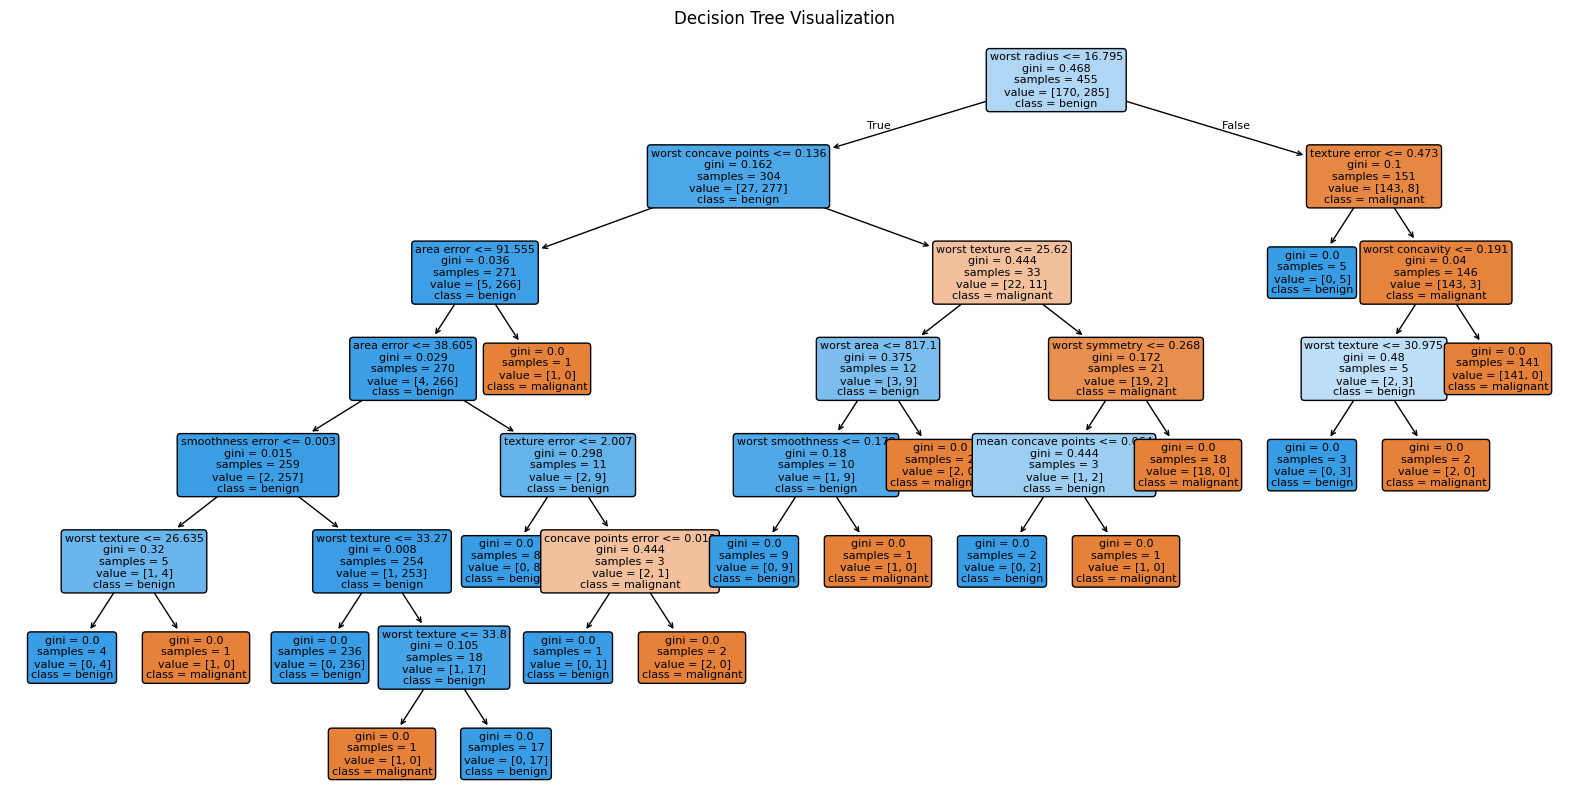

In [9]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

In [10]:
train_accuracy = dt_model.score(X_train, y_train)
test_accuracy = dt_model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy * 100, "%")
print("Testing Accuracy:", test_accuracy * 100, "%")

Training Accuracy: 100.0 %
Testing Accuracy: 91.22807017543859 %


In [11]:
dt_model_limited = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

dt_model_limited.fit(X_train, y_train)

train_acc_limited = dt_model_limited.score(X_train, y_train)
test_acc_limited = dt_model_limited.score(X_test, y_test)

print("Training Accuracy:", train_acc_limited * 100, "%")
print("Testing Accuracy:", test_acc_limited * 100, "%")

Training Accuracy: 98.68131868131869 %
Testing Accuracy: 93.85964912280701 %


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf)

Random Forest Predictions:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [14]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Accuracy Percentage:", accuracy_rf * 100, "%")

Random Forest Accuracy: 0.956140350877193
Accuracy Percentage: 95.6140350877193 %


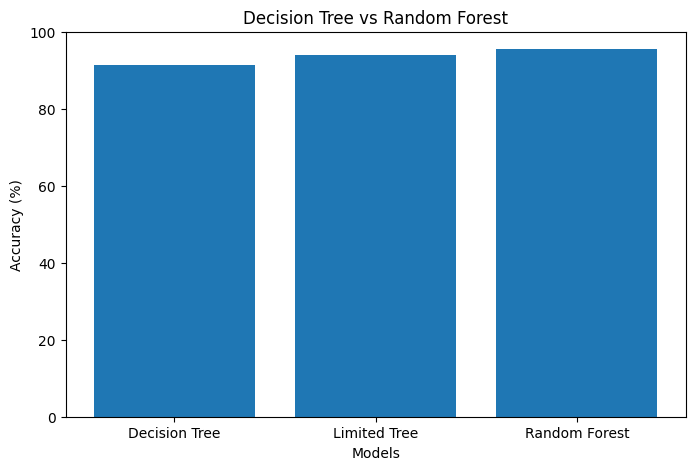

In [15]:
models = ['Decision Tree', 'Limited Tree', 'Random Forest']

accuracies = [
    accuracy_dt * 100,
    test_acc_limited * 100,
    accuracy_rf * 100
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree vs Random Forest")
plt.ylim(0, 100)

plt.show()

In [16]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(10))

                 Feature  Importance
23            worst area    0.140016
27  worst concave points    0.129530
20          worst radius    0.097696
7    mean concave points    0.090885
22       worst perimeter    0.072226
2         mean perimeter    0.069574
0            mean radius    0.068676
6         mean concavity    0.057638
3              mean area    0.049172
26       worst concavity    0.034340


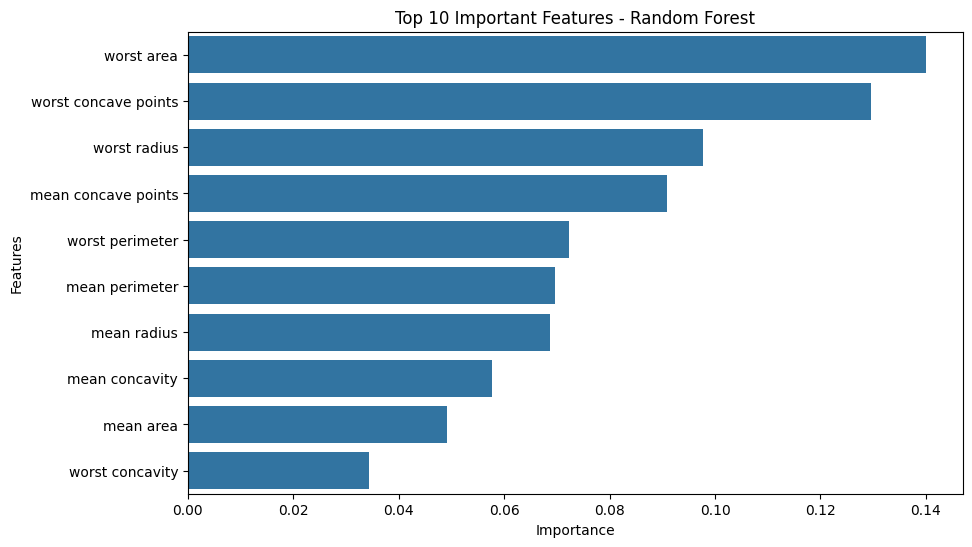

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [18]:
cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("Cross-validation scores:", cv_scores)
print("Average accuracy:", cv_scores.mean() * 100, "%")

Cross-validation scores: [0.92105263 0.93859649 0.98245614 0.96491228 0.97345133]
Average accuracy: 95.60937742586555 %


### Cross-Validation Conclusion

I performed 5-fold cross-validation using the Random Forest model.

The average cross-validation accuracy was 95.61%.

This indicates that the Random Forest model performs consistently well across different data splits.

Cross-validation helps evaluate the reliability and generalization ability of a machine learning model.

# Conclusion

In this task, I implemented Decision Tree and Random Forest models using the Breast Cancer Wisconsin dataset.

The following steps were performed:

1. Loaded and explored the dataset.
2. Checked for missing values.
3. Split the dataset into training and testing sets.
4. Trained a Decision Tree Classifier.
5. Visualized the Decision Tree.
6. Identified overfitting and controlled tree depth using max_depth.
7. Trained a Random Forest Classifier.
8. Compared the accuracy of both models.
9. Analyzed feature importance.
10. Evaluated the Random Forest model using 5-fold cross-validation.

## Final Results

- Original Decision Tree Testing Accuracy: 91.23%
- Limited Decision Tree Testing Accuracy: 93.86%
- Random Forest Testing Accuracy: 95.61%
- Random Forest Cross-Validation Accuracy: 95.61%

Random Forest achieved the highest testing accuracy among the three models.

This task helped me understand Decision Trees, Random Forests, overfitting, feature importance, and cross-validation.